In [1]:
%load_ext autoreload
%autoreload 2
%matplotlib inline

import networkx as nx

from pathlib import Path
import logging
import random
import os

import mlflow
import matplotlib.pyplot as plt
from networkx import number_weakly_connected_components
import torch
import numpy as np
from dotenv import load_dotenv

from halcyon.Simulators import NoiseLevel, SimulationResult, run_gnw


In [ ]:
seed = 174
# for CPU
torch.manual_seed(seed)
# for all GPUs
torch.cuda.manual_seed_all(seed)
np.random.seed(seed)
random.seed(seed)

load_dotenv()

mlflow.set_experiment(experiment_id="8")
# mlflow.set_experiment('Disconnected modules')
mlflow.set_experiment_tag("Tool name", "HALCYON")

In [3]:
# Assume settings is one directory up and in the setting_files directory
settings_dir = Path().resolve().parent/ "setting_files"
assert settings_dir.exists(), f"Settings directory {settings_dir.resolve()} does not exist."


In [4]:
out_path = Path().resolve().parent / 'data' / 'datasets_for_more_experiments' / 'disconnected_modules'
out_path.mkdir(parents=True, exist_ok=True)

2026-04-24 11:08:47,106 - INFO - Generating network
2026-04-24 11:08:47,796 - INFO - Loading specified settings: /lustre/BIF/nobackup/noord087/phd/HALCYON/setting_files/gnw_medium_noise.txt
Done
Start network creation of type MODULAR_SCALEFREE
Removing autoregulatory interactions from my_network
Setting dynamical model for my_network

Random initialization of my_network
my_network: Node_0: ~(Node_9~Node_12) + ~(Node_2)
my_network: Node_1: ~(Node_0*Node_16) + (Node_2)
my_network: Node_2: (Node_30) + ~(Node_1*Node_3)
my_network: Node_3: (Node_14) + (Node_2)
my_network: Node_4: ~(Node_40*Node_1*Node_8)
my_network: Node_5: ~(Node_19~Node_15) + ~(Node_35)
my_network: Node_6: (Node_24~Node_28)
my_network: Node_7: ~(Node_2) + (Node_30)
my_network: Node_8: (Node_1) + (Node_4)
my_network: Node_9: (Node_0)
my_network: Node_10: ~(Node_6~Node_27)
my_network: Node_11: (Node_7*Node_2)
my_network: Node_12: ~(Node_9) + ~(Node_0)
my_network: Node_13: (Node_8) + (Node_1) + ~(Node_4)
my_network: Node_14:

(<Figure size 640x480 with 1 Axes>, <Axes: >)

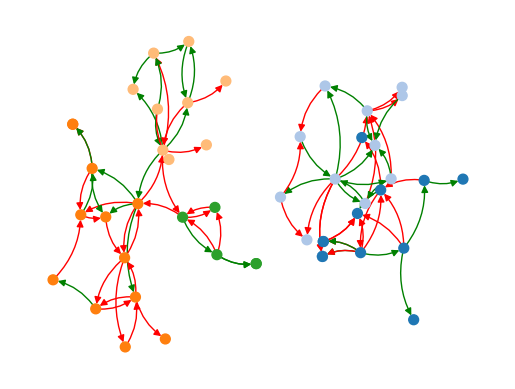

In [ ]:
nr_genes = 50
nr_modules = 5
sparsity = 0.3
keep_self_interactions = False
grouping_bias = 200
noise = NoiseLevel.MEDIUM

generated_data_path = (
    out_path
    / f"genes_{nr_genes}_modules_{nr_modules}_sparsity_{sparsity}_noise_{noise.name}"
)
generated_data_path.mkdir(parents=True, exist_ok=True)

log_location = generated_data_path / "simulation.log"
logging.basicConfig(
    level=logging.INFO,
    format="%(asctime)s - %(levelname)s - %(message)s",
    handlers=[
        logging.FileHandler(log_location),
        logging.StreamHandler(),  # also print to console
    ],
    force=True,
)
network_name = "my_network"
sim_output = run_gnw(
    settings_dir=settings_dir,
    n_genes=nr_genes,
    sparsity=sparsity,
    num_modules=nr_modules,
    network_name=network_name,
    output_path=generated_data_path,
    noise_level=noise,
    keep_self_interactions=keep_self_interactions,
    grouping_bias=grouping_bias
)

sim_output.network.do_clustering()

assert (
    number_weakly_connected_components(sim_output.network._graph) > 1
), "The generated network still fully connected."

sim_output.network.plot(separate_components=True, component_spacing=2, layout_func=nx.kamada_kawai_layout, with_labels=False, node_size=50)


In [99]:
number_weakly_connected_components(sim_output.network._graph)

2

In [ ]:
fig_path = generated_data_path / "network_plot.png"
plt.savefig(fig_path)

sim_output.save_to_pkl(generated_data_path / "simulation_result.pkl")

with mlflow.start_run(
    run_name=f"dataset_disconnected_modules"
):
    mlflow.set_tag("run_type", "dataset")
    mlflow.log_params(
        {
            "nr_genes": nr_genes,
            "sparsity": sparsity,
            "num_modules": nr_modules,
            "noise_level": noise.name,
            "seed": seed,
            'grouping_bias': grouping_bias
        }
    )
    mlflow.log_artifacts(generated_data_path, artifact_path="dataset")

